# Graph Models

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.sandbox.google.com/github/Drenderer/klax/blob/main/docs/examples/dag_model.ipynb)

This notebook demonstrates how to define and use `klax.GraphModel`s.

As an example, we'll rebuild the PANN model [[Dammaß et al. 2025](https://doi.org/10.48550/arXiv.2503.20598)] from the Isotorpic Hyperelasity example as a graph model.

In [1]:
from collections.abc import Callable
from dataclasses import dataclass
from typing import NamedTuple

import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jrandom
import optax
from jaxtyping import Array, Float
from matplotlib import pyplot as plt

import klax

We'll define Treloar's experimental data as before.

In [2]:
@dataclass
class LoadCase:
    """A simple load case."""

    stretch: Float[Array, "dim 3"]
    pk11_stress: Float[Array, "dim 1"]
    title: str


# fmt: off
# Uniaxial load case
stretch_1 = jnp.array([1.0, 1.01, 1.12, 1.24, 1.39, 1.61, 1.89, 2.17, 2.42, 3.01, 3.58, 4.03, 4.76, 5.36, 5.76, 6.16, 6.4, 6.62, 6.87, 7.05, 7.16, 7.27, 7.43, 7.5, 7.61]) 
pk11_stress = jnp.array([0.0, 0.03, 0.14, 0.23, 0.32, 0.41, 0.5, 0.58, 0.67, 0.85, 1.04, 1.21, 1.58, 1.94, 2.29, 2.67, 3.02, 3.39, 3.75, 4.12, 4.47, 4.85, 5.21, 5.57, 6.3])
stretch = jnp.stack(
    [stretch_1, stretch_1 ** (-0.5), stretch_1 ** (-0.5)], axis=-1
)

uniaxial = LoadCase(stretch, pk11_stress, "Uniaxial tension")

# Biaxial load case
stretch_1 = jnp.array([1.0, 1.04, 1.08, 1.12, 1.14, 1.2, 1.31, 1.42, 1.69, 1.94, 2.49, 3.03, 3.43, 3.75, 4.03, 4.26, 4.44])
pk11_stress = jnp.array([0.0, 0.09, 0.16, 0.24, 0.26, 0.33, 0.44, 0.51, 0.65, 0.77, 0.96, 1.24, 1.45, 1.72, 1.96, 2.22, 2.43])
stretch = jnp.stack([stretch_1, stretch_1, stretch_1 ** (-2)], axis=-1)

biaxial = LoadCase(stretch, pk11_stress, "Biaxial tension")

# Pure shear load case
stretch_1 = jnp.array([1.0, 1.06, 1.14, 1.21, 1.32, 1.46, 1.87, 2.4, 2.98, 3.48, 3.96, 4.36, 4.69, 4.96])
pk11_stress = jnp.array([0.0, 0.07, 0.16, 0.24, 0.33, 0.42, 0.59, 0.76, 0.93, 1.11, 1.28, 1.46, 1.62, 1.79])
stretch = jnp.stack(
    [stretch_1, jnp.ones_like(stretch_1), stretch_1 ** (-1)], axis=-1
)

pure_shear = LoadCase(stretch, pk11_stress, "Pure shear")
# fmt: on

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Next we define the PANN model as a `GraphModel`. We are going to use the `GraphBuilder` to simplify the process.

Any `GraphModel` consists of two parts: Parameters and a `Graph`. The former must contain all trainable parameters of the overall model, while the latter captures the computation logic of the model as a graph of interconnected building blocks.
In general, the parameters can be any arbitrary PyTree, even equinox Modules. Here, we'll use a simple `NamedTuple` as parameter container. This will allow us to access the parameters using the dot notation, e.g., `parms.icnn`. Since our model is relatively simple, the parameters will only contain one single `icnn`, but we could simply ass more parameters in the future. 

Note that the `icnn` itself contains execution logic. By making it part of the parameters (instead of the bare weights and biases) we make a conscious decision that we will not be able to extract intermediates (e.g. layer activations) using the graph interface later on. This is the intended usage of the `GraphModel`: We abstract individual reusable building blocks, like NNs, and use the graph interface to interconnect these components on a higher abstraction level.

To make our lives easier, we'll also define a helper function to initialize the parameters.

In [ ]:
class Params(NamedTuple):
    icnn: klax.nn.FICNN


def init_params(*, key):
    return Params(
        icnn=klax.nn.FICNN(
            2,
            "scalar",
            1 * [8],
            use_passthrough=True,
            non_decreasing=True,
            key=key,
        )
    )

Next, we define the graph logic. Here we have to decide how to split up the overall model logic into individual computations. Each computation is a `Block`, that maps a set of inputs to a set of outputs. We use the `GraphBuilder` to define and collect the individual blocks using a decorator.

For the computation of the `stress_coefficients`, we need to take the gradient of the energy potential. However, the computation of the energy potential is itself part of the graph. The `stress_computation` block therefore requests a GraphFunction `"isochoric_invariants -> psi_nn_normalized"` and computes the gradient of this callable.

In [4]:
g = klax.dag.GraphBuilder()


@g.block(inputs="isochoric_invariants", outputs="psi_nn")
def icnn(params: Params, isochoric_invariants: Array) -> Array:
    return params.icnn(isochoric_invariants)


@g.block(inputs="psi_nn", outputs="psi_nn_normalized")
def normalize_potential(params: Params, f: Array) -> Array:
    isochoric_invariants_iden = jnp.array([3, 4])
    pot_iden = params.icnn(isochoric_invariants_iden)
    return f - pot_iden


@g.block(
    inputs="stretch", outputs="isochoric_invariants", name="compute invariants"
)
def isochoric_invariants(params: Params, stretch: Array) -> Array:
    i1 = stretch[0] ** 2 + stretch[1] ** 2 + stretch[2] ** 2
    i2 = (
        (stretch[0] * stretch[1]) ** 2
        + (stretch[0] * stretch[2]) ** 2
        + (stretch[1] * stretch[2]) ** 2
    )
    j = stretch[0] * stretch[1] * stretch[2]

    i1_ = j ** (-2 / 3) * i1
    i2_ = j ** (-4 / 3) * i2
    return jnp.array([i1_, i2_])


@g.block(
    inputs="isochoric_invariants",
    outputs="stress_coefficients",
    uses="isochoric_invariants -> psi_nn_normalized",
    name="compute stress coefficients",
)
def stress_coefficients(
    params: Params, potential: Callable, isochoric_invariants: Array
) -> Array:
    return jax.grad(potential)(isochoric_invariants)


@g.block(
    inputs=("stretch", "stress_coefficients"),
    outputs="pk11_stress",
    name="compute Piola-Kirchhoff stress",
)
def piola_kirchhoff_stress(
    params: Params, stretch: Array, stress_coefficients: Array
):
    """Compute the (1,1) component of the Piola-Kirchoff stress."""
    return 2.0 * (
        stress_coefficients[0]
        * (stretch[0] - stretch[2] ** 2 * stretch[0] ** (-1))
        + stress_coefficients[1]
        * (
            stretch[0] * (stretch[1] ** 2 + stretch[2] ** 2)
            - stretch[2] ** 2
            * stretch[0] ** (-1)
            * (stretch[0] ** 2 + stretch[1] ** 2)
        )
    )


graph = g.build()

To check that we build the graph correctly, let's visualize it!

In [5]:
dot_code = klax.dag.to_dot(graph)

print("\n".join(dot_code.splitlines()[:7]))
print("...")

digraph G {
  rankdir=TB;
  nodesep=0.4;
  ranksep=0.5;
  node [fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=10];
  "v:isochoric_invariants" [shape=ellipse, label="isochoric_invariants", color="#d62728", penwidth=2.5];
...


Pasting this code into GraphViz, e.g., in the browser at https://graphvizonline.net/, results in:

![DAG model](../assets/dag_model.svg)

Ovals represent graph variables and rectangles the (compute-)blocks of the graph.

We can see that the computation of the potential (`psi_nn_normalized`) is just part of the overall graph, and that this part itself is used as a function inside the block "compute stress coefficients".

Finally, we define the `GraphModel` by combining the parameters and the graph.

In [ ]:
key = jrandom.PRNGKey(0)
model_key, training_key = jrandom.split(key, 2)

params = init_params(key=model_key)
model = klax.dag.GraphModel(params, graph)

To execute a graph computation, we use `model.run(have=..., want=...)`. Here have is a dictionary of the variables that we have, and want is a tuple of variables we want to compute.

With this, we can define a loss function in the usual way. This includes vmapping the graph model execution over a batch of data.

In [ ]:
@klax.loss
def loss_fn(model, batch, run_state):
    x, y = batch
    out = jax.vmap(
        lambda x: model.run(have={"stretch": x}, want="pk11_stress")
    )(x)
    y_pred = out["pk11_stress"]
    mse = jnp.mean((y - y_pred) ** 2)
    return mse, {"mse": mse}

  0%|          | 0/20000 [00:00<?, ?it/s]

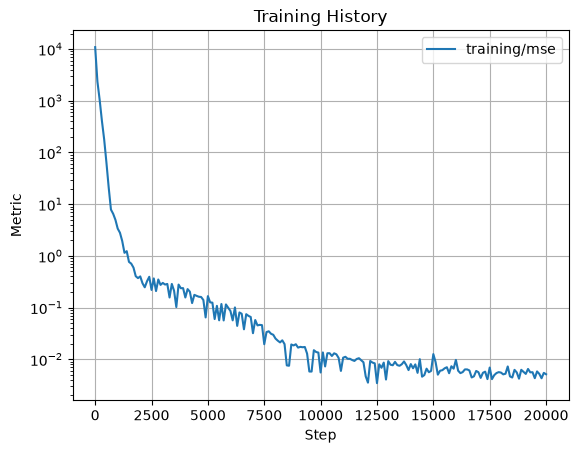

In [10]:
key = jrandom.PRNGKey(0)

x = jnp.concatenate((uniaxial.stretch, biaxial.stretch), axis=0)
y = jnp.concatenate((uniaxial.pk11_stress, biaxial.pk11_stress), axis=0)

model, history = klax.fit(
    model,
    (x, y),
    batch_size=32,
    batch_axes=0,
    steps=20_000,
    loss=loss_fn,
    optimizer=optax.adam(2e-3),
    key=training_key,
)

history.plot()
plt.show()

In [11]:
def evaluate(model, load_cases: tuple[LoadCase, ...]):
    _, axs = plt.subplots(1, len(load_cases), figsize=(5 * len(load_cases), 5))

    def plot(ax, x, y, y_pred, title):
        ax.plot(x, y, "x", label="data", color="black")
        ax.plot(x, y_pred, "-", label="data", color="blue")
        ax.set_xlabel(r"$\lambda_1$")
        ax.set_ylabel(r"$P_{11}$/ MPa")
        ax.set_title(title)

    for ax, lc in zip(axs, load_cases):
        pk11_stress_pred = eqx.filter_jit(
            jax.vmap(
                lambda x: model.run(have={"stretch": x}, want="pk11_stress")[
                    "pk11_stress"
                ]
            )
        )(lc.stretch)

        plot(ax, lc.stretch[:, 0], lc.pk11_stress, pk11_stress_pred, lc.title)

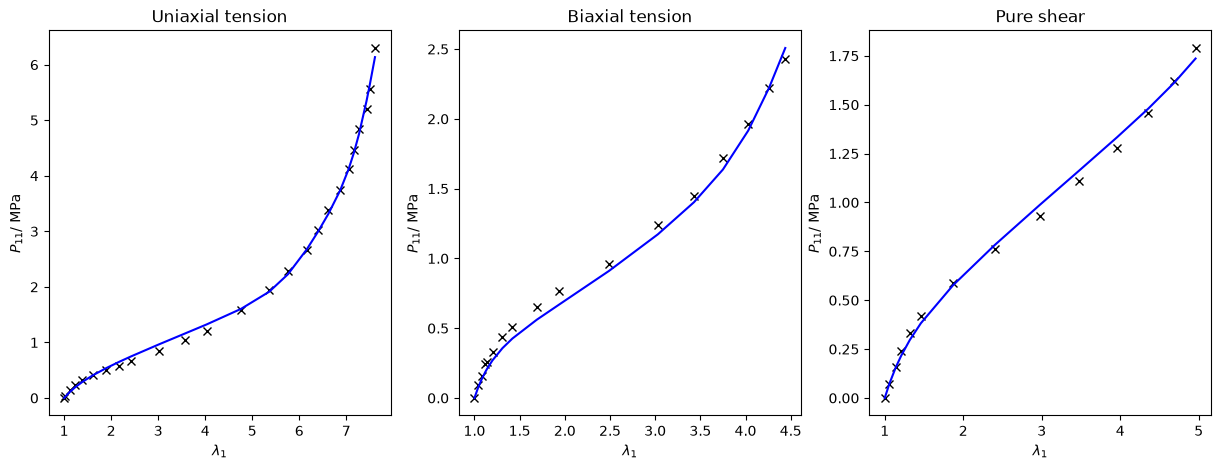

In [12]:
model_ = klax.finalize(model)
evaluate(model_, (uniaxial, biaxial, pure_shear))

To compute both the potential and the stress at once, we can simply do:

In [25]:
def evaluate(model, load_case: LoadCase):
    return jax.vmap(model.run, in_axes=(0, None))(
        {"stretch": load_case.stretch},
        ("stretch", "pk11_stress", "psi_nn_normalized", "psi_nn"),
    )


_model = klax.finalize(model)
evaluate(_model, uniaxial)

{'pk11_stress': Array([0.        , 0.00996946, 0.10815804, 0.19726273, 0.29143023,
        0.40825364, 0.53610516, 0.65115154, 0.74766177, 0.96330106,
        1.1647232 , 1.3242136 , 1.6036592 , 1.912452  , 2.228281  ,
        2.6760306 , 2.9960845 , 3.3160613 , 3.7374296 , 4.1215014 ,
        4.409997  , 4.750261  , 5.345636  , 5.6408525 , 6.1358266 ],      dtype=float32),
 'psi_nn': Array([ 1.2121234,  1.2121735,  1.2188478,  1.2373252,  1.2741696,
         1.3514935,  1.4841017,  1.650535 ,  1.82548  ,  2.330811 ,
         2.9374285,  3.4973257,  4.563188 ,  5.6114902,  6.435531 ,
         7.4121237,  8.092186 ,  8.785978 ,  9.66578  , 10.371693 ,
        10.840483 , 11.343793 , 12.149895 , 12.534311 , 13.18175  ],      dtype=float32),
 'psi_nn_normalized': Array([-2.9494762e-03, -2.8994083e-03,  3.7748814e-03,  2.2252321e-02,
         5.9096694e-02,  1.3642061e-01,  2.6902878e-01,  4.3546212e-01,
         6.1040711e-01,  1.1157382e+00,  1.7223556e+00,  2.2822528e+00,
         3.348